# 1. Problem: a corrected molecular-proximity field

Acceptor destruction changes donor quenching and reveals an ensemble FRET-efficiency field. We reconstruct the complete observed SK-BR-3 frame and estimate four correction factors from the two matched singly labelled controls and observed residual acceptor. These are real microscope observations. There is no independent molecular-efficiency truth.

The standard path below is active: it calls the cleaned modules on the raw measurements and evaluates fresh results. The archived original is loaded only for an explicitly identified comparison. Negative noisy estimates and every fixed supported pixel remain visible and scored.

In [1]:
import os,sys,time,json,tempfile,hashlib,importlib.util
from pathlib import Path
os.environ['OPENBLAS_NUM_THREADS']='1';os.environ['OMP_NUM_THREADS']='1'
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
root=Path.cwd()
if root.name=='notebooks':root=root.parent
assert (root/'src/main.py').exists()
sys.path.insert(0,str(root))
from src.main import run,load_observations
from src.preprocessing import preprocess_sample,gaussian_half_kernel,registration_shift
from src.physics_model import corrected_efficiency,donor_acquisition
from src.solvers import estimate_corrections,_display_factor
from src.visualization import image_panel,save_figure,comparison_metrics,PIXEL_UM
plt.rcParams.update({'font.size':10,'axes.titlesize':11,'figure.facecolor':'white'})
export=Path(os.environ.get('IMAGING_FIGURE_DIR',str(Path(tempfile.gettempdir())/'imaging101-fret-figures')))
index=[]
def publish(fig,name,arrays,caption):
    index.append(save_figure(fig,name,arrays,{'caption':caption,'data_role':'actual measurements and fresh local reconstruction unless explicitly identified independent analytic physics fixture','consumer':'This notebook figure and the private presentation atlas; each NPZ key is a plotted panel or plotted comparison data.'},export))
    plt.show()
raw,public_mask=load_observations(root/'data/raw_data.npz')
started=time.perf_counter();fresh=run(root);runtime=time.perf_counter()-started
E=fresh['reconstruction'][0];factors=fresh['correction_factors'][0];mask=public_mask[0]
with np.load(root/'notebooks/reference_outputs/upstream_complete.npz',allow_pickle=False) as a:upstream={k:a[k] for k in a.files}
np.savez_compressed(root/'notebooks/reference_outputs/cleaned_complete.npz',reconstruction=fresh['reconstruction'],correction_factors=fresh['correction_factors'])
spec=importlib.util.spec_from_file_location('fret_independent_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report=judge.evaluate(root/'output/reconstruction.npz')
assert report['passed'],report
(root/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False),encoding='utf8')
metrics=comparison_metrics(E,upstream['reconstruction'][0],mask)
print(json.dumps({'fresh_seconds':runtime,'supported_pixels':int(mask.sum()),'negative_efficiency_pixels_retained':int((E[mask]<0).sum()),'factors_gamma_delta_epsilon_alpha':factors.tolist(),'fresh_vs_original':metrics,'judge':report},indent=2))


{
  "fresh_seconds": 0.0955178000003798,
  "supported_pixels": 29261,
  "negative_efficiency_pixels_retained": 4446,
  "factors_gamma_delta_epsilon_alpha": [
    0.9940000176429749,
    0.014000000432133675,
    0.014999999664723873,
    0.01600000075995922
  ],
  "fresh_vs_original": {
    "ncc": 1.0,
    "dynamic_range_nrmse": 0.0,
    "max_abs": 0.0
  },
  "judge": {
    "status": "pass",
    "passed": true,
    "metrics": {
      "efficiency_ncc": 1.0,
      "efficiency_nrmse": 0.0,
      "efficiency_max_abs": 0.0,
      "factor_max_abs": 0.0
    },
    "thresholds": {
      "efficiency_ncc": {
        "comparison": ">=",
        "boundary": 0.999999999
      },
      "efficiency_nrmse": {
        "comparison": "<=",
        "boundary": 5e-07
      },
      "efficiency_max_abs": {
        "comparison": "<=",
        "boundary": 1e-06
      },
      "factor_max_abs": {
        "comparison": "<=",
        "boundary": 1e-07
      }
    },
    "errors": []
  }
}


# 2. Data: target and genuinely independent matched controls

Preparation order is donor-only, acceptor-only, doubly labelled. Each contains two channels and two time points. Raw measurements are uint16 storage of 12-bit ADU. The lateral spacing is 0.0558035714 µm. All three acquisitions have matching microscope detector gains, excitation and detection settings; calibration is not invented from a hidden target. The observed top-right rectangle supplies a separate background mean for each frame.

Only the pre-bleaching target signal defines the fixed 29,261-pixel evaluation support. It does not depend on the recovered efficiency or any later quality threshold.

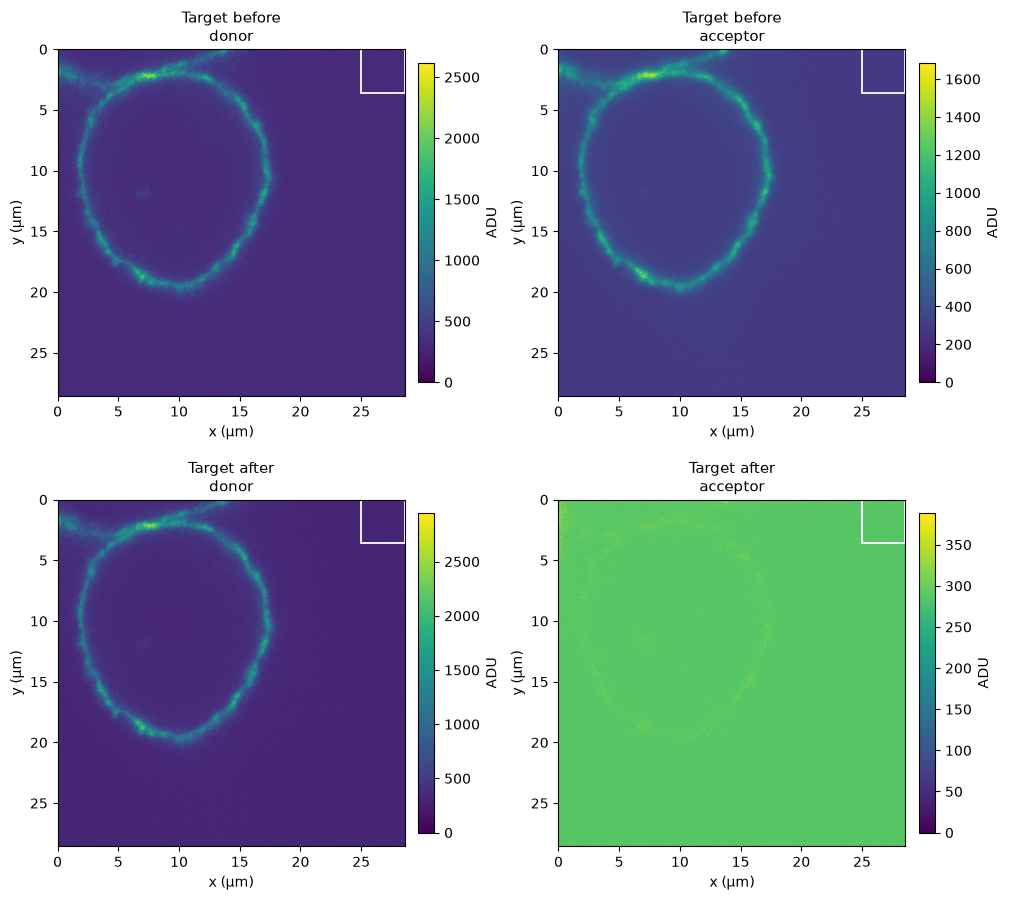

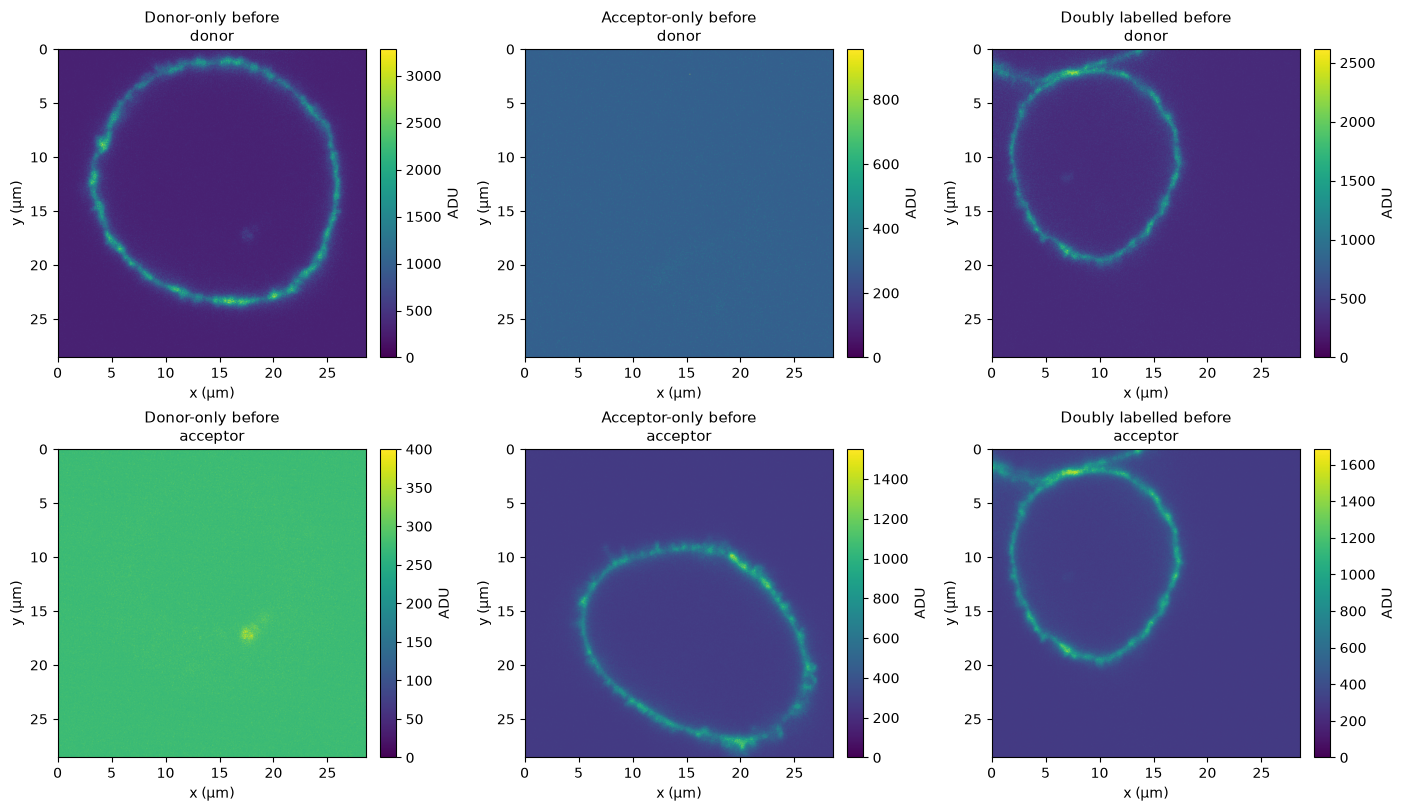

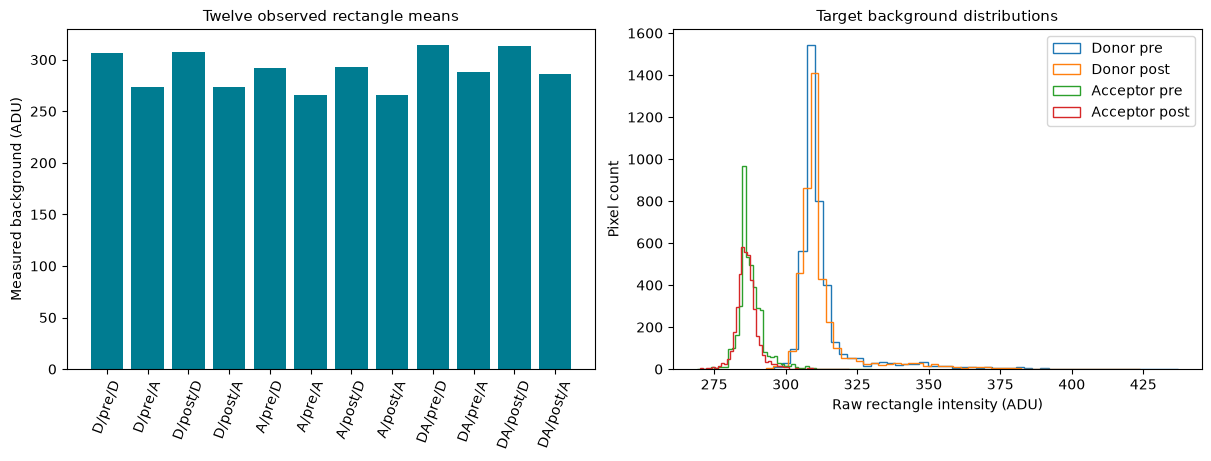

In [2]:
fig,axs=plt.subplots(2,2,figsize=(10,9),layout='constrained')
for t in range(2):
    for c in range(2):
        image_panel(axs[t,c],raw[2,t,c],f"Target {'before' if t==0 else 'after'}\n{'donor' if c==0 else 'acceptor'}")
        axs[t,c].add_patch(Rectangle((448*PIXEL_UM,0),64*PIXEL_UM,64*PIXEL_UM,fill=False,edgecolor='white',linewidth=1.3))
publish(fig,'figure01_real_target',{'target_raw_TCYX':raw[2]},'All four real target frames; white rectangle is the measured background region, never a reconstructed target region.')
fig,axs=plt.subplots(2,3,figsize=(14,8),layout='constrained')
for i,label in enumerate(['Donor-only','Acceptor-only','Doubly labelled']):
    for c in range(2):image_panel(axs[c,i],raw[i,0,c],label+' before\n'+('donor' if c==0 else 'acceptor'))
publish(fig,'figure02_independent_controls',{'before_channels_SCYX':raw[:,0]},'Independent singly labelled acquisitions and target, all observed before bleaching. Each panel retains its actual ADU range.')
fig,axs=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
offsets=np.stack([s['offsets'] for s in fresh['stages']]);labels=[f'{s}/{t}/{c}' for s in ['D','A','DA'] for t in ['pre','post'] for c in ['D','A']]
axs[0].bar(np.arange(12),offsets.ravel(),color='#007c91');axs[0].set(xticks=np.arange(12),xticklabels=labels,ylabel='Measured background (ADU)',title='Twelve observed rectangle means');axs[0].tick_params(axis='x',rotation=70)
for t,c,label in [(0,0,'Donor pre'),(1,0,'Donor post'),(0,1,'Acceptor pre'),(1,1,'Acceptor post')]:axs[1].hist(raw[2,t,c,:64,448:].ravel(),bins=50,histtype='step',label=label)
axs[1].set(xlabel='Raw rectangle intensity (ADU)',ylabel='Pixel count',title='Target background distributions');axs[1].legend()
publish(fig,'figure03_observed_background',{'offsets_STC':offsets,'target_background_TCYX':raw[2,:,:,:64,448:]},'Independent background estimates, native float32 mean subtraction and negative-count clamp. This is input preprocessing, not efficiency clipping.')


# 3. Physics: separating donor brightness from energy transfer

With dimensionless efficiency E, unquenched donor brightness D0, pre-bleaching acceptor signal A, and factors γ,δ,ε,α, the conditional physical model is

$$D_1=D_0(1-E)+\delta A,\quad D_2=D_0(1-\alpha E)/\gamma+[\alpha\delta+(1-\alpha)\epsilon]A,\quad A_2\approx\alpha A.$$

The last relation is an average model, not an assertion that every noisy pixel has identical bleaching. Gamma describes donor-only brightness change; delta and epsilon are acceptor-only leakage and photoproduct ratios. Alpha is estimated from the target's observed acceptor before/after pair, with no hidden efficiency used. The assumptions do not resolve arbitrary stoichiometry, multiple acceptor environments or a unique molecular distance.

The native integer registration peak is zero for the bound target. The following displays observed correlation and intensity differences, rather than claiming that a fitted efficiency provides independent physical proof.

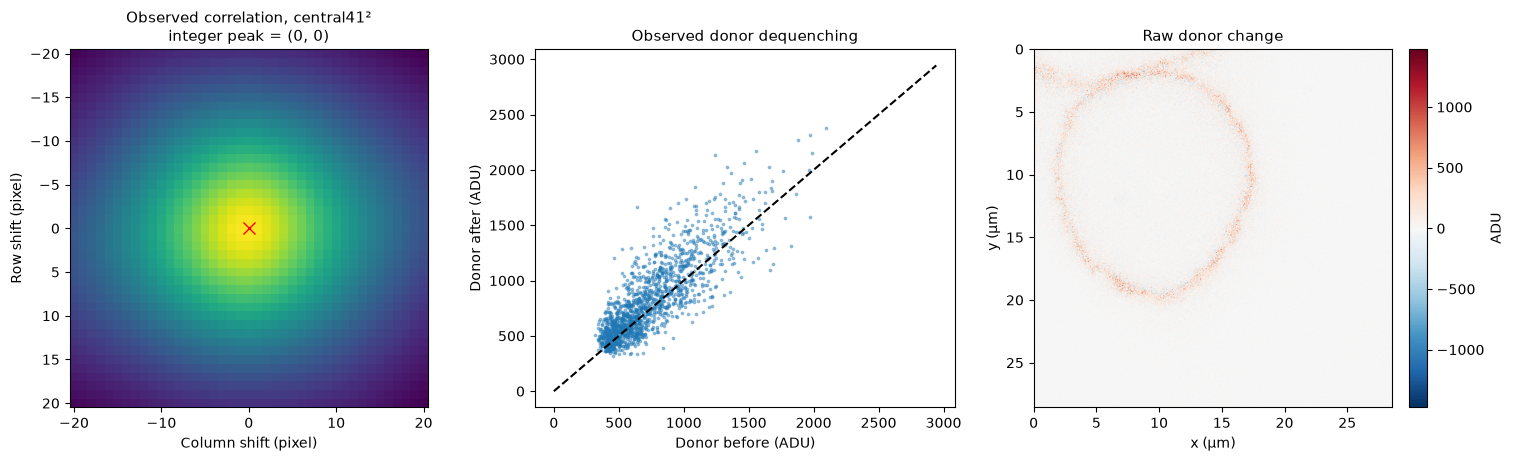

In [3]:
before=raw[2,0,0].astype(float);after=raw[2,1,0].astype(float)
corr=np.fft.fftshift(np.fft.ifft2(np.fft.fft2(before)*np.conj(np.fft.fft2(after))).real)
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
axs[0].imshow(corr[236:277,236:277],cmap='viridis',extent=(-20.5,20.5,20.5,-20.5));axs[0].plot(0,0,'rx',markersize=8);axs[0].set(title='Observed correlation, central41²\ninteger peak = (0, 0)',xlabel='Column shift (pixel)',ylabel='Row shift (pixel)')
axs[1].scatter(before[mask][::20],after[mask][::20],s=3,alpha=.4);mx=max(before[mask].max(),after[mask].max());axs[1].plot([0,mx],[0,mx],'k--');axs[1].set(xlabel='Donor before (ADU)',ylabel='Donor after (ADU)',title='Observed donor dequenching')
image_panel(axs[2],after-before,'Raw donor change','ADU',signed=True)
publish(fig,'figure04_registration_and_dequenching',{'correlation':corr,'donor_before':before,'donor_after':after,'support':mask},'Raw cross-correlation and observed donor change. Central41x41 correlation window is shown without intensity transformation; the numeric source retains the full512x512 correlation. Red cross marks the actual observed zero peak.')


# 4. Method: a complete locally evaluated closed inverse

Eliminating D0 gives

$$E=1-\frac{(1-\alpha)(D_1-\delta A)}{\gamma[D_2-(\alpha\delta+(1-\alpha)\epsilon)A]-\alpha(D_1-\delta A)}.$$

The cleaned code explicitly evaluates background correction, the finite ImageJ-compatible Gaussian half-kernel and nearest-edge convolution, matched control ratios, three-decimal correction convention and mixed float32/float64 inverse arithmetic. It uses no ImageJ or domain reconstruction library. The selected sigma is one pixel. There is no iterative optimizer or artificial convergence loop for this closed formula.

The original full CPU1 reconstruction was independently invoked twice on these exact observations; all captured stages and outputs matched bitwise before extraction. The reference remains an original-method result, not ground truth. The fresh calculation above writes all required quantities and is independently evaluated by the standalone Judge.

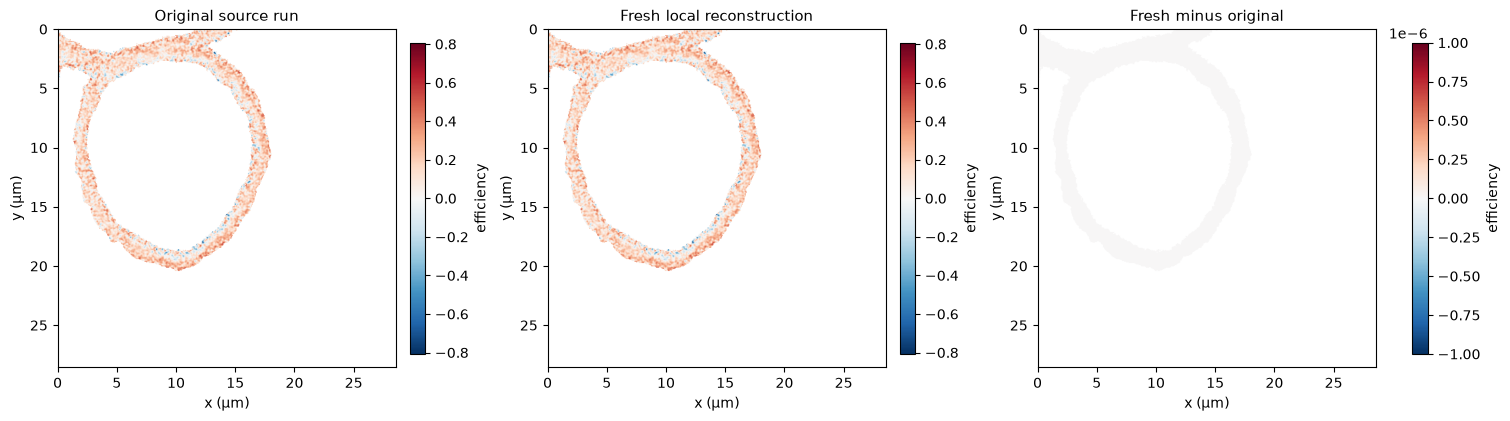

In [4]:
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
image_panel(axs[0],upstream['reconstruction'][0],'Original source run','efficiency',signed=True,mask=mask)
image_panel(axs[1],E,'Fresh local reconstruction','efficiency',signed=True,mask=mask)
image_panel(axs[2],E-upstream['reconstruction'][0],'Fresh minus original','efficiency',signed=True,mask=mask,limits=(-1e-6,1e-6))
publish(fig,'figure05_fresh_original_parity',{'original_efficiency':upstream['reconstruction'][0],'fresh_efficiency':E,'difference':E-upstream['reconstruction'][0],'support':mask},'Identified original source and active fresh reconstruction; difference has a fixed symmetric±1e-6 scale, not a fitted normalization.')


# 5. Results: correction, resolution and physical limitations

All comparisons below are freshly evaluated on the real measurements. Support stays fixed so that a method cannot improve its apparent performance by excluding difficult output pixels. Efficiency outliers and negative values remain in numeric arrays and summary statistics. A restricted display range, when used for readability, is labelled with its saturation count and never changes a scored array.

Removing a correction factor is an actual ablation of the selected physical model. It is not an independent competing estimate of biological truth. Likewise smoothing-scale experiments diagnose sensitivity, not a confidence interval.

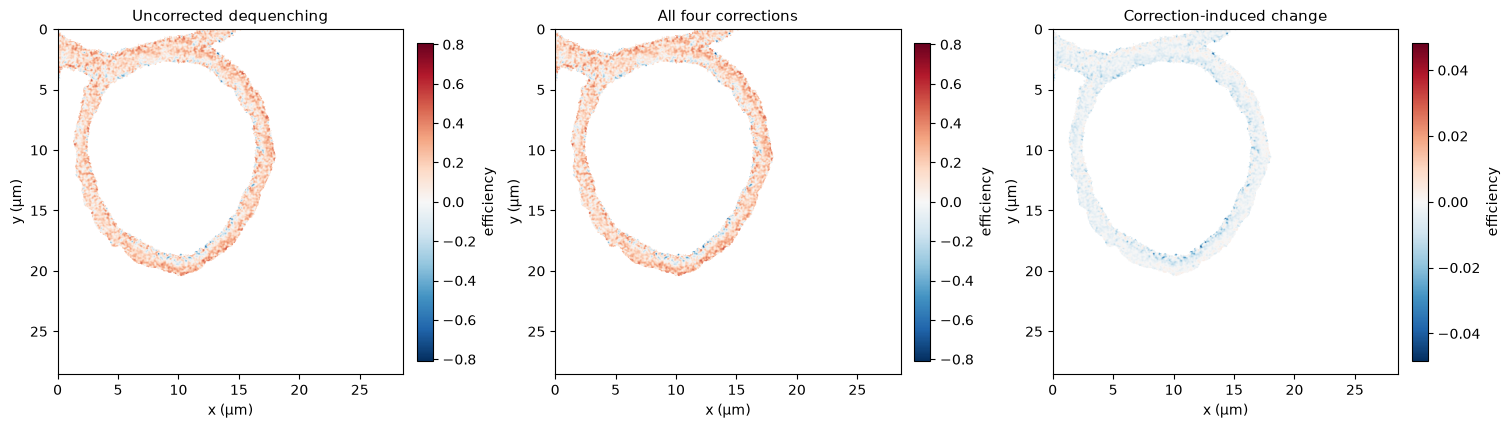

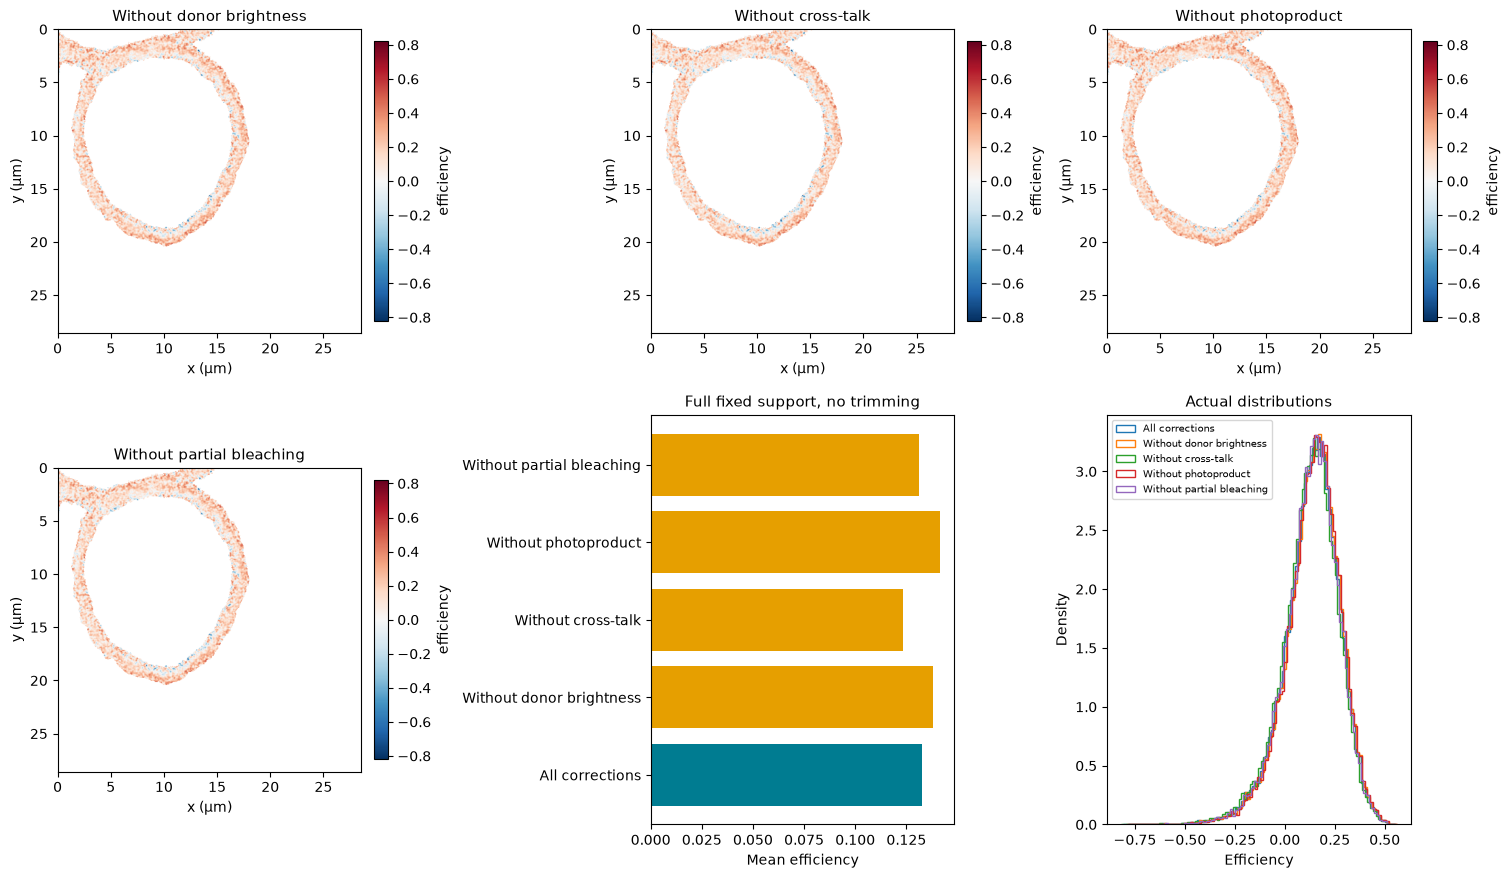

In [5]:
sm=fresh['stages'][2]['smooth'];db=sm[0,0];da=sm[1,0];ab=sm[0,1]
def field_for(fac,images=sm):
    out=np.zeros((512,512),np.float32)
    with np.errstate(divide='ignore',invalid='ignore'):out[mask]=corrected_efficiency(images[0,0][mask],images[1,0][mask],images[0,1][mask],fac)
    return out
uncorrected=field_for([1,0,0,0])
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
common=float(max(abs(uncorrected[mask]).max(),abs(E[mask]).max()))
image_panel(axs[0],uncorrected,'Uncorrected dequenching','efficiency',signed=True,mask=mask,limits=(-common,common))
image_panel(axs[1],E,'All four corrections','efficiency',signed=True,mask=mask,limits=(-common,common))
image_panel(axs[2],E-uncorrected,'Correction-induced change','efficiency',signed=True,mask=mask)
publish(fig,'figure06_complete_correction',{'uncorrected':uncorrected,'corrected':E,'difference':E-uncorrected,'support':mask},'Actual corrected versus uncorrected real field. The same fixed supported pixels and original preprocessing are used.')
ablations=[];abl_labels=[]
for j,name in enumerate(['donor brightness','cross-talk','photoproduct','partial bleaching']):
    fac=factors.copy();fac[j]=1 if j==0 else 0;ablations.append(field_for(fac));abl_labels.append('Without '+name)
fig,axs=plt.subplots(2,3,figsize=(15,9),layout='constrained')
common=float(max(np.max(abs(x[mask])) for x in [E]+ablations))
for j in range(4):image_panel(axs.flat[j],ablations[j],abl_labels[j],'efficiency',signed=True,mask=mask,limits=(-common,common))
mean_values=[float(E[mask].mean())]+[float(x[mask].mean()) for x in ablations]
axs.flat[4].barh(['All corrections']+abl_labels,mean_values,color=['#007c91']+['#e69f00']*4);axs.flat[4].set(xlabel='Mean efficiency',title='Full fixed support, no trimming')
for x,label in zip([E]+ablations,['All corrections']+abl_labels):axs.flat[5].hist(x[mask],bins=100,histtype='step',density=True,label=label)
axs.flat[5].set(xlabel='Efficiency',ylabel='Density',title='Actual distributions');axs.flat[5].legend(fontsize=7)
publish(fig,'figure07_correction_ablations',{'full':E,'ablations':np.stack(ablations),'means':np.array(mean_values),'support':mask},'Each correction is independently disabled and the inverse recomputed. Full support, signed efficiency and complete distributions are retained.')


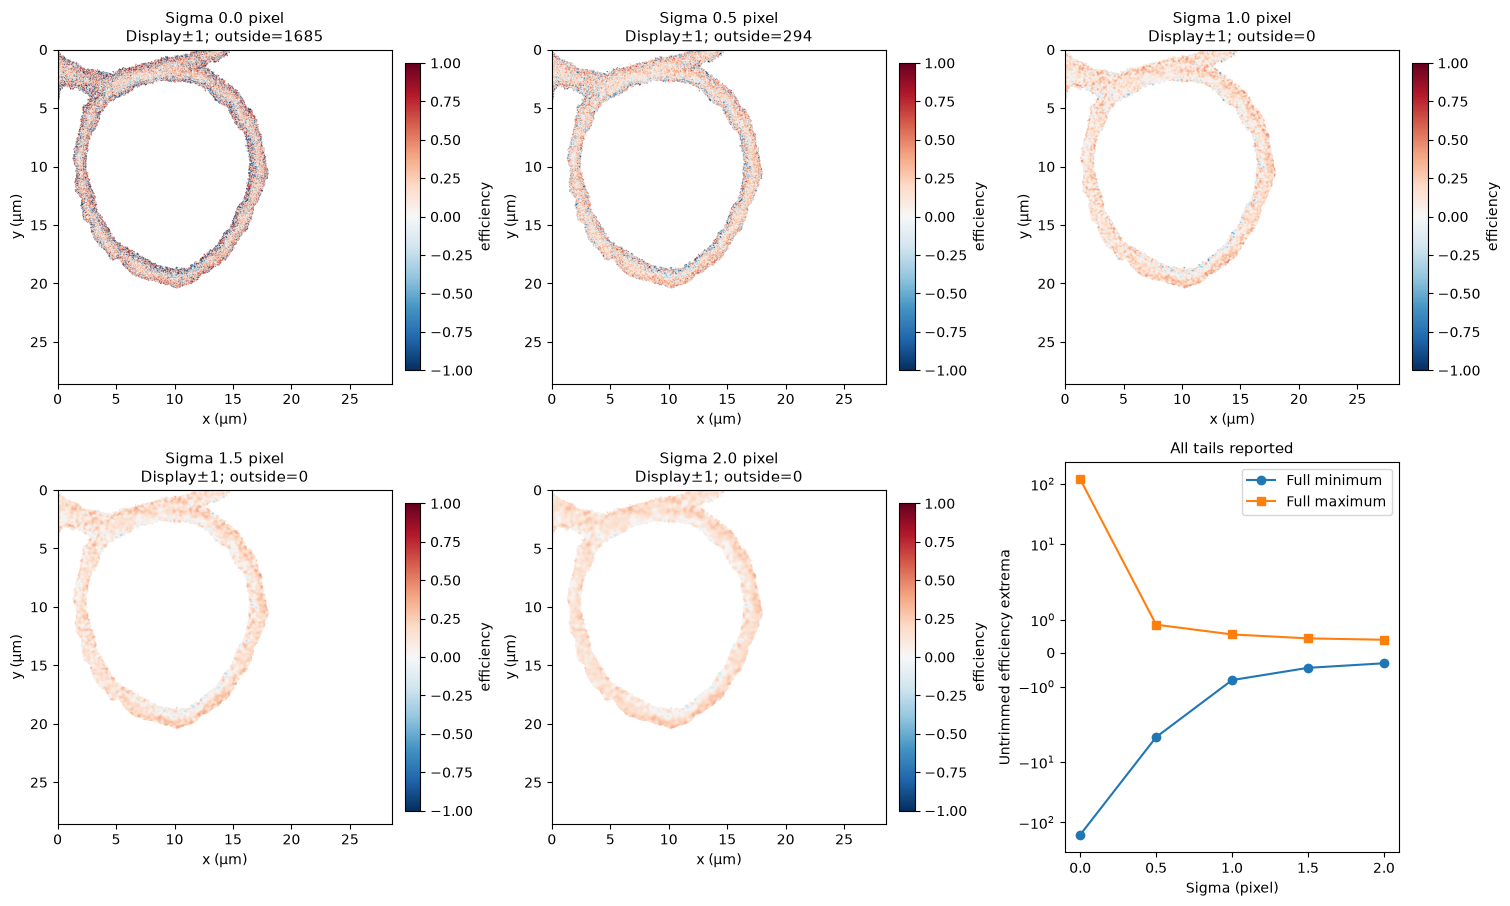

[
  {
    "sigma_pixel": 0.0,
    "nonfinite": 0,
    "minimum": -160.9727020263672,
    "maximum": 119.11613464355469,
    "median": 0.14649082720279694,
    "outside_display": 1685
  },
  {
    "sigma_pixel": 0.5,
    "nonfinite": 0,
    "minimum": -3.8475489616394043,
    "maximum": 0.8494090437889099,
    "median": 0.14620040357112885,
    "outside_display": 294
  },
  {
    "sigma_pixel": 1.0,
    "nonfinite": 0,
    "minimum": -0.8073168396949768,
    "maximum": 0.5578547716140747,
    "median": 0.14446839690208435,
    "outside_display": 0
  },
  {
    "sigma_pixel": 1.5,
    "nonfinite": 0,
    "minimum": -0.4410852789878845,
    "maximum": 0.4401628077030182,
    "median": 0.1447770595550537,
    "outside_display": 0
  },
  {
    "sigma_pixel": 2.0,
    "nonfinite": 0,
    "minimum": -0.304759681224823,
    "maximum": 0.3985021114349365,
    "median": 0.14584872126579285,
    "outside_display": 0
  }
]


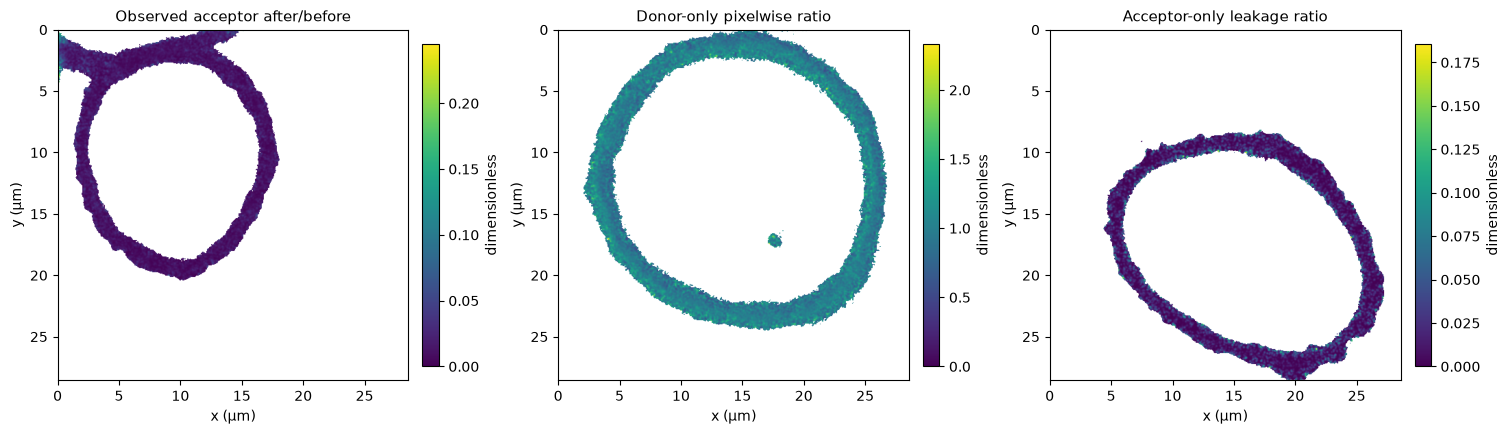

In [6]:
sigmas=[0.,.5,1.,1.5,2.];sigma_fields=[];sigma_summary=[]
fig,axs=plt.subplots(2,3,figsize=(15,9),layout='constrained')
for j,sigma in enumerate(sigmas):
    images=preprocess_sample(raw[2],sigma=sigma)['smooth'];x=field_for(factors,images);sigma_fields.append(x);v=x[mask];finite=np.isfinite(v)
    sigma_summary.append({'sigma_pixel':sigma,'nonfinite':int((~finite).sum()),'minimum':float(v[finite].min()),'maximum':float(v[finite].max()),'median':float(np.median(v[finite])),'outside_display':int((abs(v[finite])>1).sum())})
    image_panel(axs.flat[j],np.nan_to_num(x),'Sigma '+str(sigma)+' pixel\nDisplay±1; outside='+str(sigma_summary[-1]['outside_display']),'efficiency',signed=True,mask=mask,limits=(-1,1))
axs.flat[5].plot(sigmas,[s['minimum'] for s in sigma_summary],'o-',label='Full minimum');axs.flat[5].plot(sigmas,[s['maximum'] for s in sigma_summary],'s-',label='Full maximum');axs.flat[5].set(xlabel='Sigma (pixel)',ylabel='Untrimmed efficiency extrema',yscale='symlog',title='All tails reported');axs.flat[5].legend()
publish(fig,'figure08_smoothing_sensitivity',{'sigma_pixel':np.array(sigmas),'efficiency_fields':np.stack(sigma_fields),'support':mask},'Actual scale sensitivity with original factors and fixed support. Map display saturates at±1, with counts stated. Full signed tails and nonfinite counts are reported below; no variant replaces the standard field.')
print(json.dumps(sigma_summary,indent=2,allow_nan=False))
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
ratio_alpha=np.zeros((512,512));ratio_alpha[mask]=sm[1,1][mask]/sm[0,1][mask]
don=fresh['stages'][0]['smooth'];acc=fresh['stages'][1]['smooth'];dm=fresh['masks'][0]&(don[1,0]>100);am=fresh['masks'][1]
ratio_gamma=np.zeros((512,512));ratio_gamma[dm]=don[0,0][dm]/don[1,0][dm]
ratio_delta=np.zeros((512,512));ratio_delta[am]=acc[0,0][am]/acc[0,1][am]
for ax,x,m,title in zip(axs,[ratio_alpha,ratio_gamma,ratio_delta],[mask,dm,am],['Observed acceptor after/before','Donor-only pixelwise ratio','Acceptor-only leakage ratio']):image_panel(ax,x,title,'dimensionless',mask=m)
publish(fig,'figure09_spatial_control_variation',{'target_acceptor_ratio':ratio_alpha,'donor_ratio':ratio_gamma,'acceptor_leakage_ratio':ratio_delta,'target_mask':mask,'donor_common_mask':dm,'acceptor_mask':am},'Observed spatial ratio variability. Gamma/delta estimates use ratio-of-means; these noisy pixelwise ratios diagnose heterogeneity rather than replacing the selected estimator.')


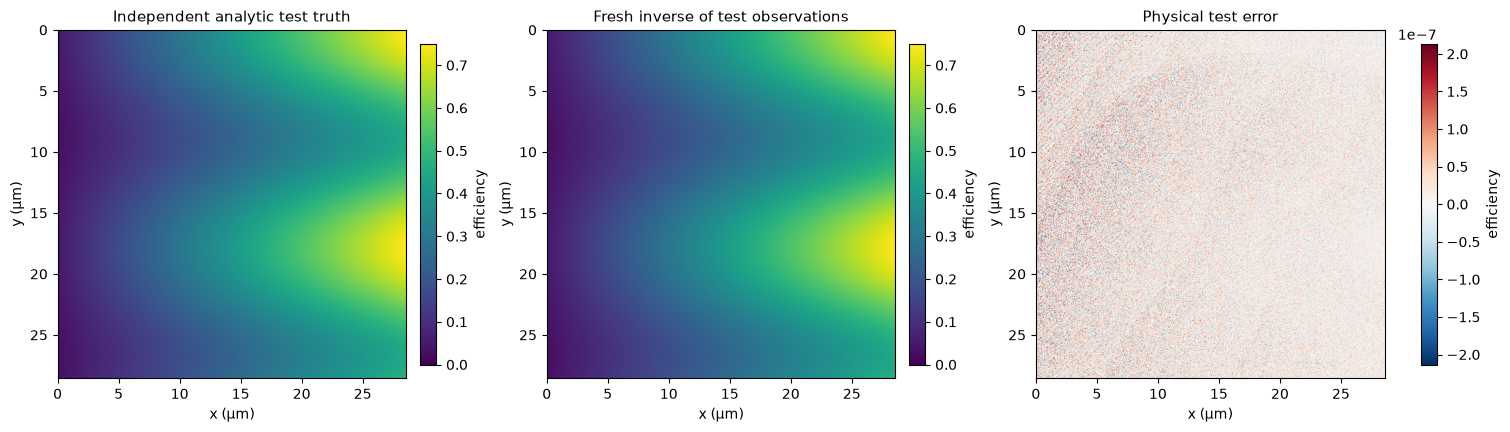

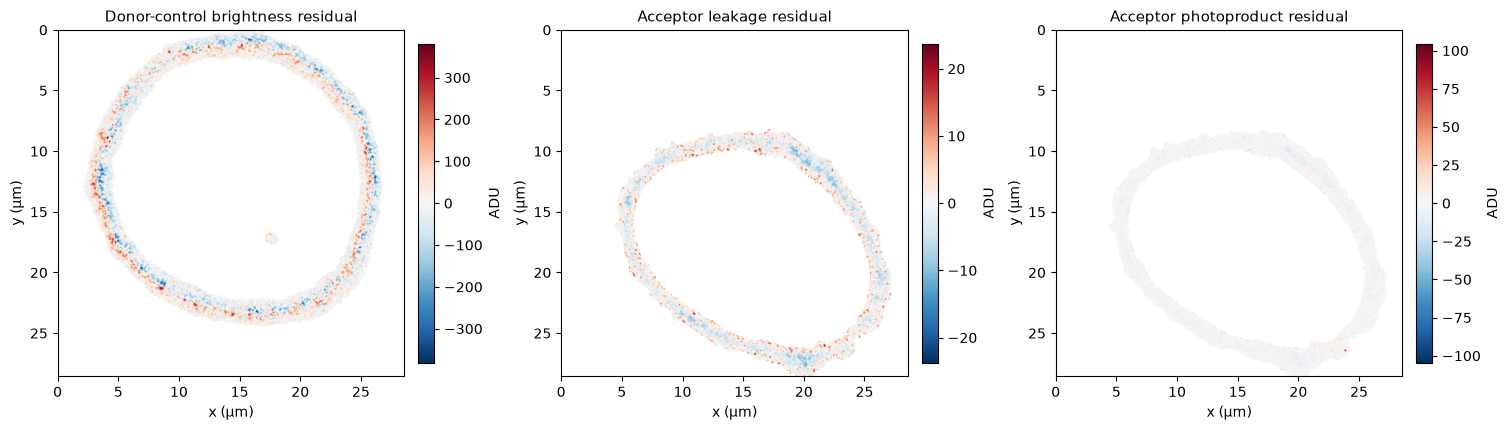

In [7]:
with np.load(root/'test/fixtures/original_known_physics.npz',allow_pickle=False) as a:known={k:a[k] for k in a.files}
ka=known['observations'];known_fresh=corrected_efficiency(ka[0],ka[2],ka[1],[.93,.07,.04,.23]);known_error=known_fresh-known['truth_efficiency']
assert np.max(abs(known_error))<4e-7
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
image_panel(axs[0],known['truth_efficiency'],'Independent analytic test truth','efficiency')
image_panel(axs[1],known_fresh,'Fresh inverse of test observations','efficiency')
image_panel(axs[2],known_error,'Physical test error','efficiency',signed=True)
publish(fig,'figure10_independent_physics',{'known_test_truth':known['truth_efficiency'],'fresh_test_inverse':known_fresh,'error':known_error,'test_observations':ka},'Separate known-E physical test, generated independently before local extraction and run through the original plugin. It is not truth for the real benchmark.')
residuals=[don[0,0]-factors[0]*don[1,0],acc[0,0]-factors[1]*acc[0,1],acc[1,0]-factors[2]*acc[0,1]]
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
for ax,x,m,title in zip(axs,residuals,[dm,am,am],['Donor-control brightness residual','Acceptor leakage residual','Acceptor photoproduct residual']):image_panel(ax,x,title,'ADU',signed=True,mask=m)
publish(fig,'figure11_control_residuals',{'residuals':np.stack(residuals),'donor_common_mask':dm,'acceptor_mask':am},'Real singly labelled residuals under the global factors. Nonzero spatial variation demonstrates noise/model limitations. Global control fits do not prove target efficiency accuracy.')


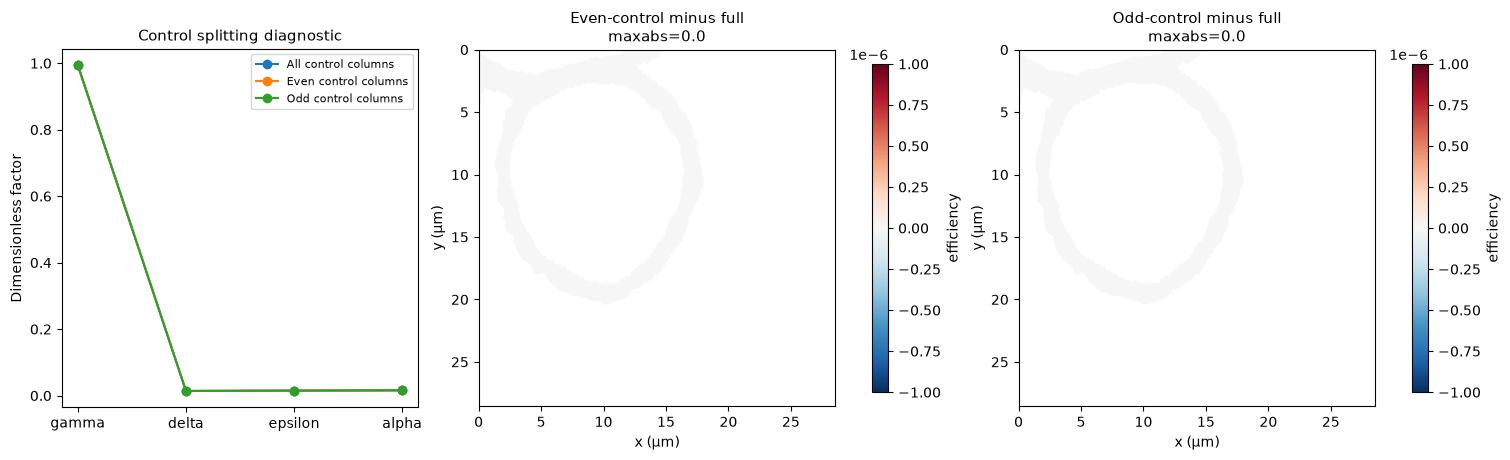

{
  "fresh_runtime_seconds": 0.0955178000003798,
  "data_sha256": "9abfacdf1d27a926b75f33c30295c7e060c8e36666a31c427f3db4bba453c29f",
  "metrics_vs_original": {
    "ncc": 1.0,
    "dynamic_range_nrmse": 0.0,
    "max_abs": 0.0
  },
  "mean_efficiency": 0.13277778198383228,
  "median_efficiency": 0.14446839690208435,
  "minimum_efficiency": -0.8073168396949768,
  "maximum_efficiency": 0.5578547716140747,
  "negative_pixels": 4446,
  "supported_pixels": 29261,
  "gamma_delta_epsilon_alpha": [
    0.9940000176429749,
    0.014000000432133675,
    0.014999999664723873,
    0.01600000075995922
  ],
  "smoothing_experiments": [
    {
      "sigma_pixel": 0.0,
      "nonfinite": 0,
      "minimum": -160.9727020263672,
      "maximum": 119.11613464355469,
      "median": 0.14649082720279694,
      "outside_display": 1685
    },
    {
      "sigma_pixel": 0.5,
      "nonfinite": 0,
      "minimum": -3.8475489616394043,
      "maximum": 0.8494090437889099,
      "median": 0.14620040357112885,
 

In [8]:
yy,xx=np.indices((512,512));half=(xx%2)==0
split_factors=[];split_fields=[]
for selection in [half,~half]:
    def mu(z,m):return np.mean(z[m&selection],dtype=np.float64)
    d1=don[0,0]>100;d2=don[1,0]>100
    fac=np.array([_display_factor(mu(don[0,0],d1)/mu(don[1,0],d2)),_display_factor(mu(acc[0,0],am)/mu(acc[0,1],am)),_display_factor(mu(acc[1,0],am)/mu(acc[0,1],am)),factors[3]],np.float32)
    split_factors.append(fac);split_fields.append(field_for(fac))
fig,axs=plt.subplots(1,3,figsize=(15,4.5),layout='constrained')
positions=np.arange(4)
for j,(fac,label) in enumerate(zip([factors]+split_factors,['All control columns','Even control columns','Odd control columns'])):axs[0].plot(positions,fac,'o-',label=label)
axs[0].set(xticks=positions,xticklabels=['gamma','delta','epsilon','alpha'],ylabel='Dimensionless factor',title='Control splitting diagnostic');axs[0].legend(fontsize=8)
image_panel(axs[1],split_fields[0]-E,'Even-control minus full\nmaxabs='+str(float(abs(split_fields[0]-E).max())),'efficiency',signed=True,mask=mask,limits=(-1e-6,1e-6))
image_panel(axs[2],split_fields[1]-E,'Odd-control minus full\nmaxabs='+str(float(abs(split_fields[1]-E).max())),'efficiency',signed=True,mask=mask,limits=(-1e-6,1e-6))
publish(fig,'figure12_matched_control_sensitivity',{'factors_full':factors,'factors_split':np.stack(split_factors),'split_efficiencies':np.stack(split_fields),'full_efficiency':E,'support':mask},'Actual matched-control interleaving sensitivity, using no target efficiency to calibrate factors. Spatially correlated pixels mean this is not an independent confidence interval. Alpha is kept at its observed target estimate.')
(export/'figure_index.json').write_text(json.dumps(index,indent=2,allow_nan=False),encoding='utf8')
measurement={'fresh_runtime_seconds':runtime,'data_sha256':hashlib.sha256((root/'data/raw_data.npz').read_bytes()).hexdigest(),'metrics_vs_original':metrics,'mean_efficiency':float(np.mean(E[mask],dtype=np.float64)),'median_efficiency':float(np.median(E[mask])),'minimum_efficiency':float(E[mask].min()),'maximum_efficiency':float(E[mask].max()),'negative_pixels':int((E[mask]<0).sum()),'supported_pixels':int(mask.sum()),'gamma_delta_epsilon_alpha':factors.tolist(),'smoothing_experiments':sigma_summary,'figures':len(index)}
(root/'notebooks/reference_outputs/cleaned_measurements.json').write_text(json.dumps(measurement,indent=2,allow_nan=False),encoding='utf8')
print(json.dumps(measurement,indent=2))


# 6. Conclusion and limits

The active reconstruction reproduces the original complete field and all four correction factors under the frozen conditional estimator. The full real target has mean efficiency about0.133 and median0.144; its noisy negative estimates are retained. The paper's manually selected membrane result is historical context, not a pixelwise truth or a required numerical target for this different fixed support.

The controls identify important corrections, but the global-factor model has spatial residuals. The observed donor factor below one records slight control brightening/noise and is not silently clamped. Strong smoothing reduces unstable local ratios while sacrificing spatial detail. Here the interleaved control estimates are identical after the selected three-decimal rounding, and both resulting fields are unchanged; this diagnostic cannot establish confidence intervals because neighbouring pixels are correlated. A simple forward/backward identity in the closed inverse would be algebraic self-consistency, so it is not presented as independent proof of molecular accuracy.

Independent known-E physics, original-stage parity, a strict standalone Judge and invalid-input tests support numerical validity. None replaces independent experimental efficiency truth, molecular stoichiometry validation or a noise characterization. All PNG/SVG/PDF plots and their exact numeric sources are exported outside the task for review.